# Figure S22: Credible-set pairing colocalization rates

Colocalized credible-set pairings by assay pair and their pooled rate.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig3_coloc](../../preparation/Fig3/build.R): Read FastENLOC result tables, assign per-pair Bayesian FDR calls, join validated variant/gene annotations and strongest posterior representatives, build credible-set components, fit current concordance and MAF-rate models, and derive S20-S23 summaries.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved credible-set pairing counts

Rebuild S22 from saved pair-level counts. A record is a tested credible-set pairing, not a unique gene or a single-assay credible set. The source calls use Bayesian FDR 5%. No new colocalization analysis is run.


In [2]:
rates <- readRDS(source_file("Fig3/data/coloc_cs_rate.rds"))
stopifnot(all(rates$n_tested >= rates$n_coloc), all(rates$n_tested > 0),
          all(abs(rates$rate - rates$n_coloc / rates$n_tested) < 1e-12))


## Calculate the pooled rate

Pool counts across assay pairs. Do not average their rates. Retain the saved pair intervals and calculate the pooled 95% Wilson interval with the formula used by the current original plot builder. The saved pair intervals also match that formula.


In [3]:
overall <- rates %>% summarise(pair = "Overall", n_tested = sum(n_tested), n_coloc = sum(n_coloc)) %>%
  mutate(rate = n_coloc / n_tested)
z <- qnorm(0.975)
wilson <- function(n, p) {
  denominator <- 1 + z^2 / n
  centre <- (p + z^2 / (2 * n)) / denominator
  half <- z * sqrt(p * (1 - p) / n + z^2 / (4 * n^2)) / denominator
  tibble(conf.low = pmax(0, centre - half), conf.high = pmin(1, centre + half))
}
pair_check <- wilson(rates$n_tested, rates$rate)
stopifnot(max(abs(pair_check$conf.low - rates$conf.low)) < 1e-12,
          max(abs(pair_check$conf.high - rates$conf.high)) < 1e-12)
overall <- bind_cols(overall, wilson(overall$n_tested, overall$rate))
summary <- bind_rows(arrange(rates, desc(rate)), overall) %>%
  mutate(pair = factor(pair, levels = pair),
         label = paste0(scales::percent(rate, accuracy = 0.1), "\n", scales::comma(n_coloc), " / ", scales::comma(n_tested)))


## Draw and save the rates

Error bars show 95% Wilson intervals. The gray Overall bar uses the summed numerator and denominator. These intervals describe saved binary pairing calls and do not include uncertainty from fine-mapping or the colocalization model.


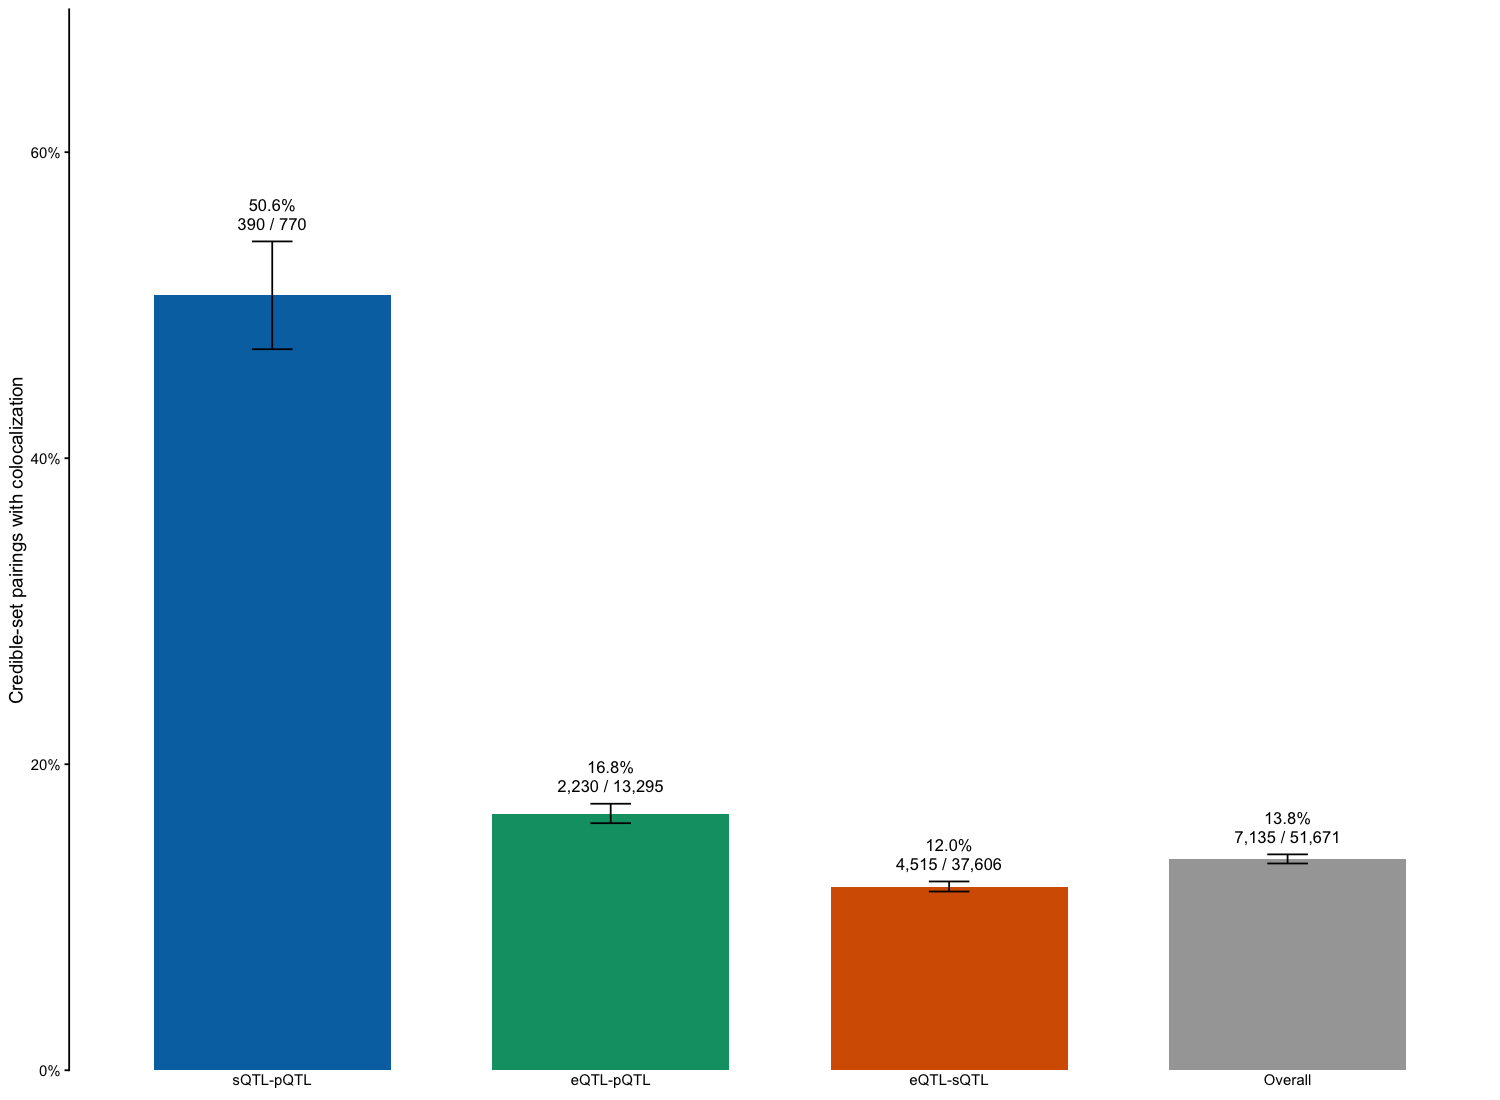

Export aggregate plot: supplements/S22


In [4]:
fills <- setNames(c("#0072B2", "#009E73", "#D55E00", "#A6A6A6"), levels(summary$pair))
figure <- ggplot(summary, aes(pair, rate, fill = pair)) +
  geom_col(width = 0.7) +
  geom_errorbar(aes(ymin = conf.low, ymax = conf.high), width = 0.12, linewidth = 0.4) +
  geom_text(aes(y = conf.high, label = label), vjust = -0.4, size = 2.8, lineheight = 0.95) +
  scale_fill_manual(values = fills, guide = "none") +
  scale_y_continuous(labels = scales::label_percent(), expand = expansion(mult = c(0, 0.28))) +
  labs(x = NULL, y = "Credible-set pairings with colocalization") + theme_classic(base_size = 9) +
  theme(axis.line.x = element_blank(), axis.ticks.x = element_blank())
print(figure)
save_plot(figure, "supplements/S22", 160, 110)
readr::write_tsv(summary %>% select(-label), output_file("supplements/S22_pairing_summary.tsv"))
